In [1]:
from torch import nn
from torch.nn import Parameter
import torch.nn.functional as F
import torch
import os
import torch_geometric
from torch_geometric.nn import ChebConv, GATConv, GCNConv, SAGEConv, TransformerConv, SuperGATConv, BatchNorm, GATv2Conv, LayerNorm, PairNorm, GCN2Conv, TAGConv
from torch_geometric.nn.inits import glorot, zeros
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from torch_geometric.data import Data
from tqdm.auto import tqdm
from torch_geometric.loader import DataLoader as graph_dataloader
from torch_geometric.utils import dense_to_sparse, remove_self_loops
from sklearn.model_selection import train_test_split
import random

In [2]:
import torch
import torch.nn as nn
import numpy as np
from sklearn.neighbors import KernelDensity
import math
import torch.linalg as linalg

# class MMD_loss(nn.Module):
#     def __init__(self, kernel_mul = 2.0, kernel_num = 5):
#         super(MMD_loss, self).__init__()
#         self.kernel_num = kernel_num
#         self.kernel_mul = kernel_mul
#         self.fix_sigma = None
#     def forward(self, source, target):
#         batch_size = int(source.size()[0])
#         kernels = guassian_kernel(source, target, kernel_mul=self.kernel_mul, kernel_num=self.kernel_num, fix_sigma=self.fix_sigma)
#         XX = kernels[:batch_size, :batch_size]
#         YY = kernels[batch_size:, batch_size:]
#         XY = kernels[:batch_size, batch_size:]
#         YX = kernels[batch_size:, :batch_size]
#         loss = torch.mean(XX + YY - XY -YX)
#         return loss
# def guassian_kernel(source, target, kernel_mul=2.0, kernel_num=5, fix_sigma=None):
#     n_samples = int(source.size()[0])+int(target.size()[0])
#     total = torch.cat([source, target], dim=0)
#     total0 = total.unsqueeze(0).expand(int(total.size(0)), int(total.size(0)), int(total.size(1)))
#     total1 = total.unsqueeze(1).expand(int(total.size(0)), int(total.size(0)), int(total.size(1)))
#     L2_distance = ((total0-total1)**2).sum(2)  
#     if fix_sigma:
#         bandwidth = fix_sigma
#     else:
#         bandwidth = torch.sum(L2_distance.data) / (n_samples**2-n_samples)
#     bandwidth /= kernel_mul ** (kernel_num // 2)
#     bandwidth_list = [bandwidth * (kernel_mul**i) for i in range(kernel_num)]
#     kernel_val = [torch.exp(-L2_distance / bandwidth_temp) for bandwidth_temp in bandwidth_list]
#     return sum(kernel_val)


# def coral(source, target):

#     d = source.size(1)  # dim vector

#     source_c = compute_covariance(source)
#     target_c = compute_covariance(target)

#     loss = torch.sum(torch.mul((source_c - target_c), (source_c - target_c)))

#     loss = loss / (4 * d * d)
#     return loss


# def compute_covariance(input_data):
#     """
#     Compute Covariance matrix of the input data
#     """
#     n = input_data.size(0)  # batch_size

#     # Check if using gpu or cpu
#     if input_data.is_cuda:
#         device = torch.device('cuda')
#     else:
#         device = torch.device('cpu')

#     id_row = torch.ones(n).resize(1, n).to(device=device)
#     sum_column = torch.mm(id_row, input_data)
#     mean_column = torch.div(sum_column, n)
#     term_mul_2 = torch.mm(mean_column.t(), mean_column)
#     d_t_d = torch.mm(input_data.t(), input_data)
#     c = torch.add(d_t_d, (-1 * term_mul_2)) * 1 / (n - 1)

#     return c

In [3]:
def seed_everything(seed = 42):   #42 #123 #0 #1 #1234
    r"""Sets the seed for generating random numbers in :pytorch:`PyTorch`,
    :obj:`numpy` and Python.

    Args:
        seed (int): The desired seed.
    """
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed) # if you are using multi-GPU.
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
# df_source = pd.read_csv('Data/fusion_tona_supervised_captor_raptor_2017.csv', sep = ';')
# df_target = pd.read_csv('Data/fusion_tona_supervised_captor_raptor_2018.csv', sep = ';')
# df_target = pd.read_csv('Data/fusion_pr_supervised_2019.csv', sep = ';')
# df_target = pd.read_csv('AirQuality Data/station_12001.csv')
# df_source = pd.read_csv('AirQuality Data/station_22009.csv')

# df_target = pd.read_csv('Data/captor17017-TONA.csv')
# df_source = pd.read_csv('Data/captor17013-MANLLEU.csv')

df_target = pd.read_csv('Data/R-69.csv', sep = ';')
df_source = pd.read_csv('Data/R-212.csv', sep = ';')

# def df_column_switch(df, column1, column2):
#     i = list(df.columns)
#     a, b = i.index(column1), i.index(column2)
#     i[b], i[a] = i[a], i[b]
#     df = df[i]
#     return df

# df_source = df_column_switch(df_source, 'ref_o3', 'ref_no2')
# df_target = df_column_switch(df_target, 'ref_o3', 'ref_no2')

pd.set_option('display.max_columns', None)

In [5]:
# df_mets = pd.read_csv('AirQuality Data/Meteorology_id_2206.csv')
# df_mett = pd.read_csv('AirQuality Data/Meteorology_id_1201.csv')

In [6]:
# df_source['time'] = pd.to_datetime(df_source['time'])
# df_mets['time'] = pd.to_datetime(df_mets['time'])
# df_source['date'] = df_source['time'].dt.date
# df_mets['date'] = df_mets['time'].dt.date

In [7]:
# # Merge DataFrames based on the 'date' column
# merged_source = pd.merge(df_source, df_mets, on='time', how='inner')
# del merged_source['date_x']
# del merged_source['id']
# del merged_source['date_y']
# del merged_source['weather']


In [8]:
# df_target['time'] = pd.to_datetime(df_target['time'])
# df_mett['time'] = pd.to_datetime(df_mett['time'])
# df_target['date'] = df_target['time'].dt.date
# df_mett['date'] = df_mett['time'].dt.date

# # Merge DataFrames based on the 'date' column
# merged_target = pd.merge(df_target, df_mett, on='time', how='inner')
# del merged_target['date_x']
# del merged_target['id']
# del merged_target['date_y']
# del merged_target['weather']

In [9]:
# def interpolate_with_threshold(df, max_consecutive_missing=5):
#     for column in df.columns:
#         missing_mask = df[column].isnull()
#         consecutive_missing = missing_mask.groupby((~missing_mask).cumsum()).cumsum()

#         # Drop rows with consecutive missing values greater than the threshold
#         df = df[consecutive_missing <= max_consecutive_missing]

#         # Interpolate remaining missing values
#         df[column] = df[column].interpolate()

#     return df

In [10]:
# df_source = interpolate_with_threshold(merged_source)
# df_target = interpolate_with_threshold(merged_target)

In [11]:
# # Calculate the percentage of missing values per column
# missing_percentage = (df_source.isnull().sum() / len(df_target)) * 100

# # Create a DataFrame to display the results
# missing_info = pd.DataFrame({
#     'Column': missing_percentage.index,
#     'Missing Percentage': missing_percentage.values
# })

# # Display the missing information
# print(missing_info)

# df_source = df_source.iloc[:,2:]
# df_target = df_target.iloc[:,2:]

In [12]:
# import os
# import pandas as pd

# folder_path = 'AirQuality Data'  # Replace with the actual path to your folder

# missing_info = []

# for file_name in os.listdir(folder_path):
#     if file_name.endswith('.csv'):
#         file_path = os.path.join(folder_path, file_name)
#         df = pd.read_csv(file_path)
#         missing_percentage = (df.isnull().sum().sum() / (df.shape[0] * df.shape[1])) * 100

#         missing_info.append((file_name, missing_percentage))

# # Sort files by missing percentage
# sorted_missing_info = sorted(missing_info, key=lambda x: x[1])

# # Report sorted files
# for file_name, missing_percentage in sorted_missing_info:
#     print(f"File: {file_name}, Missing Percentage: {missing_percentage:.2f}%")


In [13]:
# # df_source.drop('date', axis = 1, inplace = True)
# # df_target.drop(['date', 'no2_raw'], axis = 1, inplace = True)
# # df_target.rename(columns={"Temp": "temp", "RH": "hr"}, inplace = True)

# df_source.drop('date', axis = 1, inplace = True)
# df_target.drop('date', axis = 1, inplace = True)


# feature_columns = df_source.columns

# # Define figure size and subplot layout
# plt.figure(figsize=(12, 8))
# num_features = len(feature_columns)
# rows = 2
# cols = 3

# # Define colors for histograms
# colors = ['blue', 'orange']

# # Plot each feature distribution
# for i, feature in enumerate(feature_columns, 1):
#     plt.subplot(rows, cols, i)
#     plt.hist(df_source[feature], bins=20, color=colors[0], alpha=0.7, label='Source')
#     plt.hist(df_target[feature], bins=20, color=colors[1], alpha=0.7, label='Target')
#     plt.title(f'Distribution of {feature}', fontsize=12)
#     plt.xlabel('Feature Values', fontsize=10)
#     plt.ylabel('Frequency', fontsize=10)
#     plt.xticks(fontsize=8)
#     plt.yticks(fontsize=8)
#     plt.legend(fontsize=8)

# # Adjust layout
# plt.tight_layout()

# # Show plot

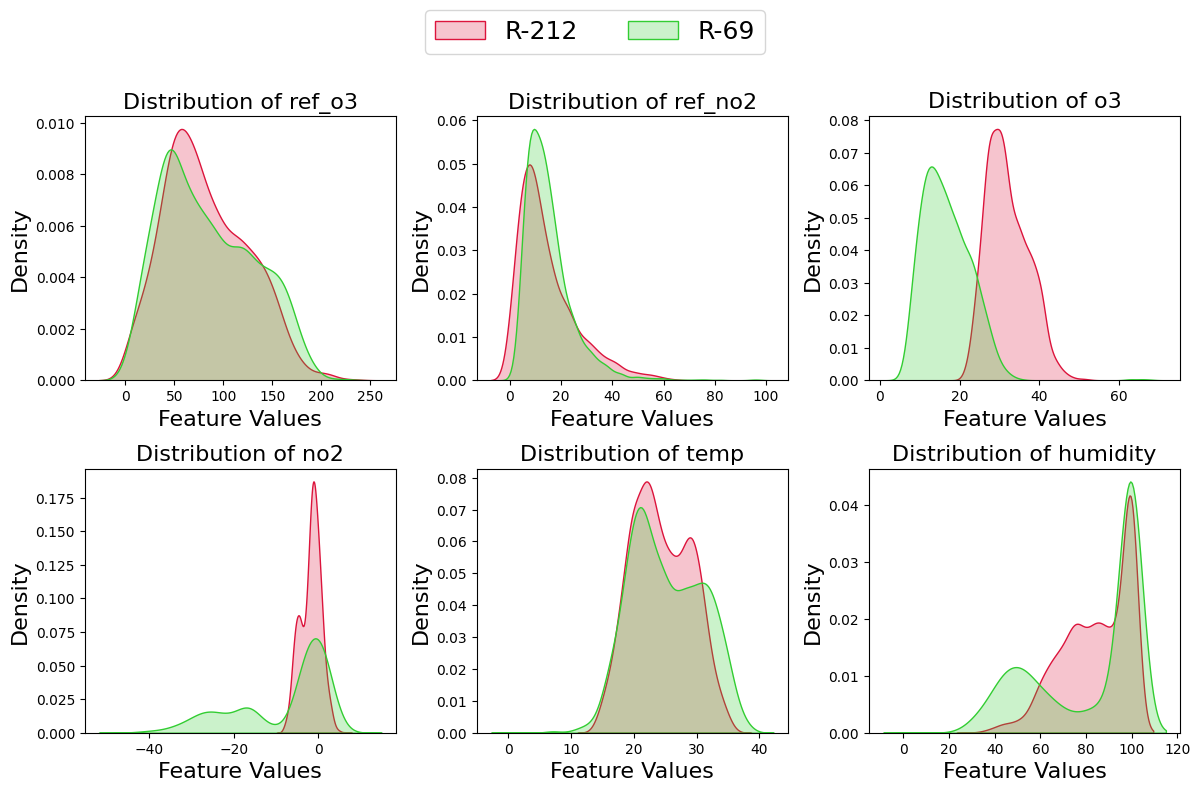

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

df_source.drop('date', axis = 1, inplace = True)
df_target.drop('date', axis = 1, inplace = True)


feature_columns = df_source.columns

# Define figure size and subplot layout
fig, axs = plt.subplots(2, 3, figsize=(12, 8))

# Store the handles and labels for the legend
handles = []
labels = []

# Plot each feature distribution using KDE plots
for i, feature in enumerate(feature_columns):
    row = i // 3
    col = i % 3
    
    # Plot KDEs for source and target data in each subplot
    source_plot = sns.kdeplot(df_source[feature], color='crimson', label='R-212', fill=True, ax=axs[row, col])
    target_plot = sns.kdeplot(df_target[feature], color='limegreen', label='R-69', fill=True, ax=axs[row, col])
    
    # Set plot title and labels
    axs[row, col].set_title(f'Distribution of {feature}', fontsize=16)
    axs[row, col].set_xlabel('Feature Values', fontsize=16)
    axs[row, col].set_ylabel('Density', fontsize=16)
    axs[row, col].tick_params(axis='both', labelsize=10)
    
    # Only gather handles and labels from the first subplot
    if i == 0:
        handles, labels = source_plot.get_legend_handles_labels()
    
    # Remove legends from each subplot
    axs[row, col].legend().remove()

# Add a single legend at the top of the figure
fig.legend(handles, labels, loc='upper center', fontsize=18, bbox_to_anchor=(0.5, 1), ncol=2)

# Adjust layout and margins
plt.tight_layout(rect=[0, 0, 1, 0.9])  # Adjusting the top margin

# Save plot as a PDF
plt.savefig('distribution_plots.pdf', format='pdf', transparent=True, bbox_inches='tight')

# Show plot
plt.show()


In [15]:
# def swap_columns(df, col1, col2):
#     col_list = list(df.columns)
#     x, y = col_list.index(col1), col_list.index(col2)
#     col_list[y], col_list[x] = col_list[x], col_list[y]
#     df = df[col_list]
#     return df

# df_source = swap_columns(df_source, 'PM25_Concentration', 'O3_Concentration')
# df_target = swap_columns(df_target, 'PM25_Concentration', 'O3_Concentration')

In [16]:
train_ratio_source = int(1 * len(df_source.index))
val_ratio_source = int(0.0* len(df_source.index))
df_train_source = df_source.iloc[:train_ratio_source,:]
df_test_source = df_source.iloc[train_ratio_source:,:]

df_train_min = df_train_source.min()
df_train_max = df_train_source.max()

# normalized_df_source=(df_source-df_train_min)/(df_train_max-df_train_min)
# df_train_source = normalized_df_source.iloc[:train_ratio_source]
# df_test_source = normalized_df_source.iloc[train_ratio_source+val_ratio_source:]

train_ratio_target = int(1 * len(df_target.index))
val_ratio_target = int(0.0* len(df_target.index))
df_train_target = df_target.iloc[:train_ratio_target,:]
df_test_target = df_target.iloc[train_ratio_target:,:]


In [17]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

# Normalization (Source)
scaler_ts = MinMaxScaler()
scaler_ty = MinMaxScaler()

scaler_ty.fit(df_train_source.iloc[:,0].values.reshape(-1, 1))


df_train_source = np.array(df_train_source)
df_train_source = scaler_ts.fit_transform(df_train_source)
# df_X_val_source = np.array(df_X_val_source)
# df_X_val_source = scaler_ts.transform(df_X_val_source)
# df_test_source = np.array(df_test_source)
# df_test_source = scaler_ts.transform(df_test_source)


#Target

df_train_target = np.array(df_train_target)
df_train_target = scaler_ts.transform(df_train_target)
# df_X_val_source = np.array(df_X_val_source)
# df_X_val_source = scaler_ts.transform(df_X_val_source)
# df_test_target = np.array(df_test_target)
# df_test_target = scaler_ts.transform(df_test_target)

In [18]:
window_size = 16  #16

def create_sequences(values, time_steps = window_size):
    output = []
    for i in range(len(values) - time_steps + 1):
        output.append(values[i : (i + time_steps)])
    return np.stack(output)

In [19]:
# def prepare_forecasting_dataset(df, window_size = window_size, forecast_window=1):
#     sequences = []

#     for i in range(len(df) - window_size - forecast_window + 1):
#         sequence = df.iloc[i:i + window_size, :].to_numpy()
#         sequences.append(sequence)

#     sequences = np.array(sequences)
#     labels = df.iloc[window_size + forecast_window - 1:, :].to_numpy()

#     # Create PyTorch tensors
#     data_tensor = torch.from_numpy(sequences)
#     label_tensor = torch.from_numpy(labels)

#     return torch.utils.data.TensorDataset(data_tensor, label_tensor)

In [20]:
# data_x_y_train_source =prepare_forecasting_dataset(df_train_source)
# data_x_y_test_source =prepare_forecasting_dataset(df_test_source)
# data_x_y_train_target =prepare_forecasting_dataset(df_train_target)
# data_x_y_test_target =prepare_forecasting_dataset(df_test_target)

In [21]:
df_train_tensor_source = torch.from_numpy(df_train_source[:,1:])
df_train_tensor_source = create_sequences(df_train_tensor_source)
df_train_tensor_label_source = torch.from_numpy(df_train_source[:,0])
df_train_tensor_label_source = create_sequences(df_train_tensor_label_source)
print(df_train_tensor_source.shape)
print(df_train_tensor_label_source.shape)
data_x_y_train_source = torch.utils.data.TensorDataset(torch.from_numpy(df_train_tensor_source), torch.from_numpy(df_train_tensor_label_source))

# df_test_tensor_source = torch.from_numpy(df_test_source[:,1:])
# df_test_tensor_source = create_sequences(df_test_tensor_source)
# df_test_tensor_label_source = torch.from_numpy(df_test_source[:,0])
# df_test_tensor_label_source = create_sequences(df_test_tensor_label_source)
# print(df_test_tensor_source.shape)

# data_x_y_test_source = torch.utils.data.TensorDataset(torch.from_numpy(df_test_tensor_source), torch.from_numpy(df_test_tensor_label_source))

(2133, 16, 5)
(2133, 16)


In [22]:
df_train_tensor_target = torch.from_numpy(df_train_target[:,1:])
df_train_tensor_target = create_sequences(df_train_tensor_target)
df_train_tensor_label_target = torch.from_numpy(df_train_target[:,0])
df_train_tensor_label_target = create_sequences(df_train_tensor_label_target)
data_x_y_train_target = torch.utils.data.TensorDataset(torch.from_numpy(df_train_tensor_target), torch.from_numpy(df_train_tensor_label_target))

# df_test_tensor_target = torch.from_numpy(df_test_target[:,1:])
# df_test_tensor_target = create_sequences(df_test_tensor_target)
# df_test_tensor_label_target = torch.from_numpy(df_test_target[:,0])
# df_test_tensor_label_target = create_sequences(df_test_tensor_label_target)
# data_x_y_test_target = torch.utils.data.TensorDataset(torch.from_numpy(df_test_tensor_target), torch.from_numpy(df_test_tensor_label_target))

# print(df_train_tensor_target.shape)
# print(df_train_tensor_label_target.shape)
# print(df_test_tensor_target.shape)
# print(df_test_tensor_label_target.shape)

In [23]:
train_dl_source = torch.utils.data.DataLoader(data_x_y_train_source, batch_size = 64, shuffle = False, drop_last = True)
# val_dl_source = torch.utils.data.DataLoader(data_x_y_test_source, batch_size= 32, shuffle = False)
# test_dl_source = torch.utils.data.DataLoader(data_x_y_test_source, batch_size= 1, shuffle = False)
val_dl_source = torch.utils.data.DataLoader(data_x_y_train_source, batch_size= 64, shuffle = False)
test_dl_source = torch.utils.data.DataLoader(data_x_y_train_source, batch_size= 1, shuffle = False)

train_dl_target = torch.utils.data.DataLoader(data_x_y_train_target, batch_size = 64, shuffle = False, drop_last = True)
# test_dl_target = torch.utils.data.DataLoader(data_x_y_test_target, batch_size= 1, shuffle = False)
val_dl_target = torch.utils.data.DataLoader(data_x_y_train_target, batch_size= 64, shuffle = False)
test_dl_target = torch.utils.data.DataLoader(data_x_y_train_target, batch_size= 1, shuffle = False)

In [24]:
## Main Function

In [25]:
def similarity(u, v):
    cos_sim = nn.CosineSimilarity(dim=0,eps=1e-6)
    cosine_sim = torch.clamp(cos_sim(u, v), -1., 1.)
    similarity = 1-torch.sqrt(0.5*(1-cosine_sim))
    return similarity
        
    

def TIK_LOSS(H1, H2, treshold = 0.9, tradeoff_angle = 0.01 , tradeoff_scale = 0.005):     #0.01  0.005
    b,p = H1.shape

    A = torch.cat((torch.ones(b,1).to(device), H1), 1)
    B = torch.cat((torch.ones(b,1).to(device), H2), 1)

    # A = H1     Somewhat same performance, why torch.cat is added?
    # B = H2

    cov_A = (A.t()@A) +(1*torch.eye((A.t()@A).shape[0]).to(device))
    cov_B = (B.t()@B) + (1*torch.eye((B.t()@B).shape[0]).to(device))

    _,L_A,_ = torch.linalg.svd(cov_A)
    _,L_B,_ = torch.linalg.svd(cov_B)
    
    # eigen_A = torch.cumsum(L_A.detach(), dim=0)/L_A.sum()
    # eigen_B = torch.cumsum(L_B.detach(), dim=0)/L_B.sum()

    # if(eigen_A[1]>treshold):
    #     T = eigen_A[1].detach()
    # else:
    #     T = treshold
        
    # index_A = torch.argwhere(eigen_A.detach()<=T)[-1]

    # if(eigen_B[1]> treshold):
    #     T = eigen_B[1].detach()
    # else:
    #     T = treshold

    # index_B = torch.argwhere(eigen_B.detach()<=T)[-1]
    
    # k = max(index_A, index_B)[0]

    # A = torch.linalg.pinv(cov_A ,rtol = (L_A[k]/L_A[0]).detach())
    # B = torch.linalg.pinv(cov_B ,rtol = (L_B[k]/L_B[0]).detach())
    
    # A = torch.linalg.pinv(cov_A).detach()
    # B = torch.linalg.pinv(cov_B).detach()

    A = torch.linalg.inv(cov_A).detach()  #If alpha is super small, matrix can be numerically instable, so replace inv with pinv
    B = torch.linalg.inv(cov_B).detach()
    
    cos = torch.dist(torch.ones((p+1)).to(device),(similarity(A,B)),p=1)/(p+1)
    return tradeoff_angle*(cos) + tradeoff_scale*torch.dist((L_A[:1]),(L_B[:1]))/1

In [26]:
def R_eta(input,eta=0.04):

    sing = torch.linalg.svdvals(input)
    rank = torch.sum((1-torch.exp(-sing/eta)))

    return rank


In [27]:
from tsl.nn.blocks.encoders import RNN
from tsl.nn.layers import NodeEmbedding, DiffConv, GATConv
from einops.layers.torch import Rearrange  # reshape data with Einstein notation
seed_everything()

class FGNN(nn.Module):
    def __init__(self, input_size = 1, n_nodes = 5, horizon = 1,
                 hidden_size: int = 16,
                 rnn_layers: int = 4,    #5 was good for tikhonov
                 gnn_kernel: int = 2):
        super().__init__()

        self.encoder = nn.Linear(input_size, hidden_size)

        self.node_embeddings = NodeEmbedding(n_nodes, hidden_size)

        self.time_nn = RNN(input_size=hidden_size,
                           hidden_size=hidden_size,
                           n_layers=rnn_layers,
                           cell='gru',
                           return_only_last_state=True)
        
        self.space_nn = GATConv(in_channels=hidden_size,
                                 out_channels=hidden_size)

        self.decoder = nn.LazyLinear(horizon)
        # self.rearrange = Rearrange('b n (t f) -> b t n f', t=horizon)

    def forward(self, x):
        x = x.unsqueeze(3)
        # x: [batch time nodes features]
        batch = x.shape[0]
        x_enc = self.encoder(x)  # linear encoder: x_enc = xΘ + b
        x_emb = x_enc + self.node_embeddings()  # add node-identifier embeddings
        # pre1 = x_emb
        h = self.time_nn(x_emb)  # temporal processing: x=[b t n f] -> h=[b n f]
        # pre1 = h.reshape(-1, h.shape[-1])
        A = torch.ones(h.shape[1], h.shape[1])
        edge_index = (A > 0).nonzero().t().to(device)
        out = self.space_nn(h, edge_index = edge_index , need_weights = True)  # spatial processing
        z = out[0]
        pre2 = z
        alpha = out[1]
        alpha = torch_geometric.utils.to_dense_adj(edge_index = alpha[0], edge_attr = alpha[1]).squeeze()
        alpha = alpha.reshape(-1, batch).T

        pre1 = alpha
        
        x_out = self.decoder(z.flatten(start_dim = 1))  # linear decoder: z=[b n f] -> 
        return x_out, pre1, pre2

In [28]:
eg = next(iter(train_dl_source))
eg[0].size(), eg[1].size()

(torch.Size([64, 16, 5]), torch.Size([64, 16]))

In [29]:
seed_everything()
model = FGNN().to(device)
eg_out = model(eg[0].float().to(device))
eg_out[0].size(), eg_out[1].size()

/home/faghih/.local/lib/python3.10/site-packages/torch/nn/modules/lazy.py:180: UserWarning: Lazy modules are a new feature under heavy development so changes to the API or functionality can happen at any moment.
  warnings.warn('Lazy modules are a new feature under heavy development '


(torch.Size([64, 1]), torch.Size([64, 25]))

In [30]:
seed_everything()
model = FGNN().to(device)


optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)



EPOCHS = 150
best_loss = float('inf')



best_model = None
patience = 150
counter = 0

for epoch in range(EPOCHS):
    seed_everything()
    model.train()
    train_losses = []
    current_losses = []
    p = (epoch)/(EPOCHS)
    alpha_ = 2. / (1. + np.exp(-10 * p)) - 1
    # Training loop
    for idx, (data_source, data_target) in (enumerate(zip(train_dl_source,train_dl_target))):
        
        input_target, label_target = data_target
        input_source, label_source = data_source

        
        optimizer.zero_grad()
        # optimizer_d.zero_grad()
        out, pre, feat = model(input_source.float().to(device))
        out_t, pre_t, feat_t = model(input_target.float().to(device))

        _,s,_ = torch.svd(feat.flatten(start_dim=1))
        # _, s ,_ = torch.svd(feat)
        # _, s_t ,_ = torch.svd(feat_t)
        
        # d_s = model_domain(feature,alpha_)
        # d_t = model_domain(feature_t,alpha_)
        # domain_source_labels = torch.zeros(d_s.shape[0]*4).type(torch.LongTensor).cuda()
        # domain_target_labels = torch.ones(d_t.shape[0]*4).type(torch.LongTensor).cuda()
        
        loss = F.mse_loss(out.squeeze(), label_source[:,-1].float().squeeze().to(device)) + alpha_ * TIK_LOSS(feat.flatten(start_dim = 1),feat_t.flatten(start_dim = 1))

        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())
       
        
    # # Early MMD()
    # train_losses = np.array(train_losses)
    # current_loss1 = DARE_GRAM_LOSS(feat.flatten(start_dim = 1),feat_t.flatten(start_dim = 1))
    # current_losses.append(current_loss1.item())
    # current_losses = torch.from_numpy(np.array(current_losses)).to(device)

    # if current_losses < best_loss:
            
    #     best_loss = current_losses
    #     best_model_state_dict = model.state_dict()
    #     torch.save(best_model_state_dict, 'best_model_2.pth')
    #     print('best adaptation')
    #     counter = 0  # Reset the counter if there's improvement
    # else:
    #     counter += 1  # Increment the counter if there's no improvement
            
    # # Check if we should stop training due to lack of improvement
    # if counter >= patience:
    #     print(f'Early stopping at epoch {epoch+1} due to lack of improvement in MMD loss.')
    #     break
        
    train_losses = np.array(train_losses)
    recon_epoch_loss = ((train_losses).mean())

    total_epoch_loss = recon_epoch_loss

    # Print progress at every 10 epochs
    if (epoch + 1) % 5 == 0:

        print(f"Epoch: {epoch+1}")
        print('Training Loss:', recon_epoch_loss)


    # Validation loop
    cost = 0
    with torch.inference_mode():
        model.eval()
        preds_list = []
        targets_list = []
        for idx, (data_input, data_label) in (enumerate(val_dl_source)):  
            y_pred= model(data_input.float().to(device))[0]
            y_pred = y_pred.squeeze()
            preds_list.append(y_pred)
            targets_list.append(data_label)
            cost = cost + torch.mean((y_pred.squeeze() - data_label[:,-1].float().squeeze().to(device))**2)
        cost = cost / (idx+1)
        cost = cost.item()

    val_losses = np.array(cost)
    recon_epoch_loss_eval = np.sqrt((val_losses).mean())

    total_epoch_loss_eval = recon_epoch_loss_eval



    # Print progress at every 10 epochs
    if (epoch + 1) % 5 == 0:
        print('Validation Loss:', recon_epoch_loss_eval)

    # Test loop
    cost = 0
    with torch.inference_mode():
        model.eval()
        preds_list = []
        targets_list = []
        for idx, (data_input, data_label) in (enumerate(val_dl_target)):  
            y_pred= model(data_input.float().to(device))[0]
            y_pred = y_pred.squeeze()
            preds_list.append(y_pred)
            targets_list.append(data_label)
            cost = cost + torch.mean((y_pred.squeeze() - data_label.float()[:,-1].squeeze().to(device))**2)
        cost = cost / (idx+1)
        cost = cost.item()

    val_losses = np.array(cost)
    recon_epoch_loss_eval = np.sqrt((val_losses).mean())

    total_epoch_loss_eval = recon_epoch_loss_eval
    

    if (epoch + 1) % 5 == 0:
        print('Test Loss:', np.sqrt((np.array(cost)).mean()))

    # if (epoch + 1) in epochs_to_save:
    #     torch.save(model.state_dict(), f'model(DAREGRAM+TA)_epoch_{epoch+1}.pth')
    #     print(f'Model saved at epoch {epoch+1}')
    
    
#     # Early stopping
#     if total_epoch_loss_eval < best_loss:
#         best_loss = total_epoch_loss_eval
#         torch.save(model.state_dict(), 'best_model_2.pth')
#         # print('best model')
#         print('Best model saved')
#         #print(recon_epoch_loss_eval)
#         counter = 0
#     else:
#         counter += 1
#         if counter >= patience:
#             print('Early stopping')
#             break
# # Load the best model
# best_model_state_dict = torch.load('best_model_2.pth')
# model.load_state_dict(best_model_state_dict)

Epoch: 5
Training Loss: 0.035012046891179954
Validation Loss: 0.18211606059655042
Test Loss: 0.2009590652901216
Epoch: 10
Training Loss: 0.035326794467189095
Validation Loss: 0.18198688891562584
Test Loss: 0.20067682742107384
Epoch: 15
Training Loss: 0.035233275118199264
Validation Loss: 0.18194534009934654
Test Loss: 0.20053601929930515
Epoch: 20
Training Loss: 0.03495768037144885
Validation Loss: 0.18195206593933735
Test Loss: 0.20051224904862427
Epoch: 25
Training Loss: 0.03483763128293283
Validation Loss: 0.1819748520971987
Test Loss: 0.20052466863622181
Epoch: 30
Training Loss: 0.03461237759752707
Validation Loss: 0.18197437101733124
Test Loss: 0.20049617768506506
Epoch: 35
Training Loss: 0.03458448270843788
Validation Loss: 0.18191902810811142
Test Loss: 0.20035123568080723
Epoch: 40
Training Loss: 0.03453646329316226
Validation Loss: 0.18197611108742834
Test Loss: 0.2004812292316439
Epoch: 45
Training Loss: 0.034501514877333786
Validation Loss: 0.18194527867500462
Test Loss: 0.2

In [31]:
# best_model_state_dict = torch.load('best_model_2.pth')
# model.load_state_dict(best_model_state_dict)

In [32]:
with torch.inference_mode():
    
    model.eval()
    pred = []
    gt = []
    
    for batch_idx, batch in enumerate(tqdm(test_dl_target)):
        x = batch[0].to(device).float()
        y = batch[1].to(device).float()
        recons = model(x)[0]
        pred.append(recons.detach().cpu().numpy())
        gt.append(y.detach().cpu().numpy())
        recon_loss = F.mse_loss(y.squeeze()[-1], recons.squeeze())
        loss = recon_loss
    
    pred = np.concatenate(pred, axis=0).squeeze()
    # pred = (pred)
    # pred_new = pred[:,-1,:]
    gt = np.concatenate(gt, axis=0)
    gt= np.array(gt[:,-1])

  0%|          | 0/2280 [00:00<?, ?it/s]

In [33]:
max_val = np.array(df_train_max[0])
min_val = np.array(df_train_min[0])

gt_denormalized = scaler_ty.inverse_transform(gt.reshape(-1, 1))
pred_denormalized = scaler_ty.inverse_transform(pred.reshape(-1, 1))

In [34]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

print(f"NRMSE: {mean_squared_error(pred,gt, squared = False)}")
print(f"NMAE: {mean_absolute_error(pred,gt)}")
pred_denormalized = pred_denormalized.squeeze()


print(f"RMSE: {mean_squared_error(pred_denormalized,gt_denormalized, squared = False)}")
print(f"MAE: {mean_absolute_error(pred_denormalized,gt_denormalized)}")

NRMSE: 0.08876834809780121
NMAE: 0.07114721089601517
RMSE: 20.709653854370117
MAE: 16.598644256591797


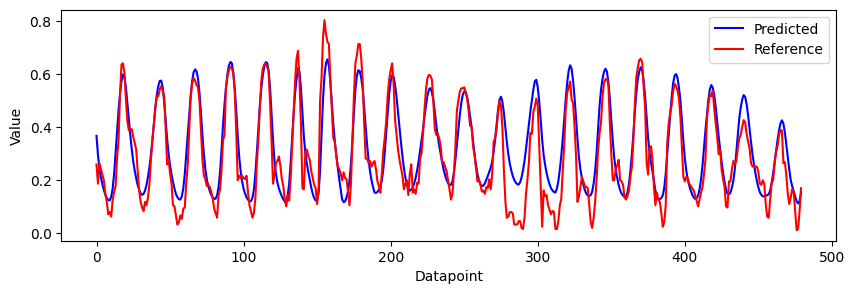

In [35]:
plt.figure(figsize=(10, 3))
plt.plot(pred[1800:], linestyle = 'solid', color = 'blue', label = 'Predicted')
plt.plot(gt[1800:], linestyle = 'solid', color = 'red', label = 'Reference')
plt.legend()
plt.ylabel('Value')
plt.xlabel('Datapoint')
plt.show()